# 03 · Candidate Generation and Feature Engineering

**Round 1 demo:** show how one GPS observation becomes 12 possible road arcs, how the candidate feature values are calculated, and why those features are meaningful for map matching.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
ROOT=Path.cwd()
if not (ROOT/"src").exists(): ROOT=ROOT.parent
sys.path.insert(0,str(ROOT/"src"))
DATA=ROOT/"data"/"Student folder"
print("Project:",ROOT,"| dataset found:",DATA.exists())

Project: /Users/yashas/Documents/Codex/2026-11-18/referenced-chatgpt-conversation-this-is-an-2/ML_hackathon | dataset found: True


## Step 1 — Build road-segment geometry in local metres

Each arc points from one node row to another. After converting node coordinates to metres, each arc is a line segment. A KD-tree over segment midpoints narrows the search; exact point-to-segment projection then calculates distance.

In [2]:
import numpy as np,pandas as pd
from pathsnap.data import read_trip
from pathsnap.matcher import generate_candidates,FEATURE_NAMES,_geometry,_xy,_point_segment_distance
trip=read_trip(DATA/"train"/"00000001","train")
lon0,lat0,arc_ids,starts,ends,vectors,lengths=_geometry(trip)
print({"GPS_points":len(trip.track),"valid_nonzero_road_arcs":len(arc_ids),"feature_count":len(FEATURE_NAMES),"features":FEATURE_NAMES})
print("coordinate origin:",(lon0,lat0),"local road segment example (m):",starts[0],ends[0])

{'GPS_points': 1315, 'valid_nonzero_road_arcs': 165782, 'feature_count': 5, 'features': ['distance_m', 'heading_difference_rad', 'along_segment_fraction', 'segment_length_m', 'gps_speed_mps']}
coordinate origin: (8.603564, 50.128292) local road segment example (m): [ -1561.80101598 -29891.34248   ] [ -1638.01776193 -29907.1497    ]


## The exact feature calculation for one candidate

For a point $p$, segment start $a$, and segment vector $v=b-a$, project onto the segment with $t=clip(((p-a)\cdot v)/(v\cdot v),0,1)$. The nearest point is $a+tv$ and distance is its Euclidean distance from $p$. We also compare the direction of the GPS step with the candidate arc direction using the wrapped angular difference. The next cell reproduces those calculations for one observation and one candidate; `generate_candidates` applies the same formulas in vectorized form to all observations.


In [3]:
# Reproduce the vectorized feature formulas for the first GPS observation/candidate.
point = _xy(trip.track[:1, :2], lon0, lat0)[0]
midpoints = (starts + ends) / 2
_, nearby_rows = __import__("scipy.spatial", fromlist=["cKDTree"]).cKDTree(midpoints).query(point, k=12)
nearby_rows = np.atleast_1d(nearby_rows)
row = int(nearby_rows[0])
segment_start, segment_vector = starts[row], vectors[row]
segment_length = lengths[row]
t = np.clip(np.dot(point - segment_start, segment_vector) / (segment_length ** 2), 0, 1)
nearest_point = segment_start + t * segment_vector
distance_m = np.linalg.norm(point - nearest_point)

# First GPS displacement gives the local motion heading (0 if no previous step).
gps_xy = _xy(trip.track[:, :2], lon0, lat0)
step = gps_xy[1] - gps_xy[0] if len(gps_xy) > 1 else np.zeros(2)
gps_heading = np.arctan2(step[1], step[0])
road_heading = np.arctan2(segment_vector[1], segment_vector[0])
heading_difference_rad = abs((road_heading - gps_heading + np.pi) % (2 * np.pi) - np.pi)
segment_length_m = segment_length
gps_speed_mps = np.linalg.norm(step) / max(float(trip.track[1, 2] - trip.track[0, 2]), 1.0) if len(gps_xy) > 1 else 0.0
print({"arc_id": int(arc_ids[row]), "distance_m": round(float(distance_m), 2),
       "heading_difference_rad": round(float(heading_difference_rad), 3),
       "along_segment_fraction": round(float(t), 3),
       "segment_length_m": round(float(segment_length_m), 2),
       "gps_speed_mps": round(float(gps_speed_mps), 2)})


{'arc_id': 117639, 'distance_m': 15.01, 'heading_difference_rad': 3.12, 'along_segment_fraction': 0.513, 'segment_length_m': 1014.51, 'gps_speed_mps': 43.38}


## Step 2 — Generate the candidate set and check coverage

For each observation, query the 12 nearest segment midpoints. The final distance feature is measured to the finite segment, not to its midpoint. We measure candidate miss rate against the trip’s reference route.

In [4]:
batch=generate_candidates(trip,k=12)
print({"candidate_array_shape":batch.ids.shape,"candidate_miss_observations":int(batch.candidate_miss.sum()),"observations":len(batch.truth),"candidate_miss_rate":float(batch.candidate_miss.mean())})
obs=10; ref=int(batch.truth[obs])
view=pd.DataFrame(batch.features[obs],columns=FEATURE_NAMES)
view.insert(0,"candidate_arc_id",batch.ids[obs]);view["is_reference_arc"]=batch.ids[obs]==ref
print("reference arc ID for observation:",ref)
display(view.sort_values("distance_m").reset_index(drop=True))

{'candidate_array_shape': (1315, 12), 'candidate_miss_observations': 240, 'observations': 1315, 'candidate_miss_rate': 0.18250950570342206}
reference arc ID for observation: 8970


,candidate_arc_id,distance_m,heading_difference_rad,along_segment_fraction,segment_length_m,gps_speed_mps,is_reference_arc
0,8970,3.327852,0.064054,0.023994,167.862518,37.617348,True
1,133950,5.224627,0.064908,1.000000,27.416754,37.617348,False
2,139208,31.622494,0.065726,1.000000,63.631401,37.617348,False
3,133949,95.138580,0.066111,1.000000,57.610889,37.617348,False
4,68262,149.057190,0.380472,1.000000,2.499920,37.617348,False
5,68265,149.057190,2.761121,0.000000,2.499920,37.617348,False
6,68264,149.057190,0.188497,0.000000,26.081347,37.617348,False
7,68267,149.057190,2.953096,1.000000,26.081347,37.617348,False
8,68263,149.238831,2.026734,0.000000,5.099653,37.617348,False
9,68260,149.238831,1.114859,1.000000,5.099653,37.617348,False


## Step 3 — Compare feature values for correct and alternative candidates

A training target is 1 when the candidate arc equals the closest arc in the supplied reference route, and 0 for other candidates. Missed observations have no positive candidate and are counted separately.

In [5]:
labels=(batch.ids==batch.truth[:,None]) & (batch.truth[:,None]>=0)
long=pd.DataFrame(batch.features.reshape(-1,len(FEATURE_NAMES)),columns=FEATURE_NAMES)
long["is_reference_candidate"]=labels.reshape(-1)
print("Candidate-level feature summaries:")
display(long.groupby("is_reference_candidate")[FEATURE_NAMES].agg(["median","mean"]).round(3))

Candidate-level feature summaries:


distance_m            heading_difference_rad         \
                           median       mean                 median   mean   
is_reference_candidate                                                       
False                   39.860001  50.983002                  1.618  1.612   
True                     4.176000   4.895000                  0.107  0.184   

                       along_segment_fraction        segment_length_m  \
                                       median   mean           median   
is_reference_candidate                                                  
False                                   0.499  0.500        36.383999   
True                                    0.499  0.499       102.135002   

                                   gps_speed_mps             
                              mean        median       mean  
is_reference_candidate                                       
False                    62.458000     41.275002  37.921001  
True                    169.949997     39.807999  36.487999

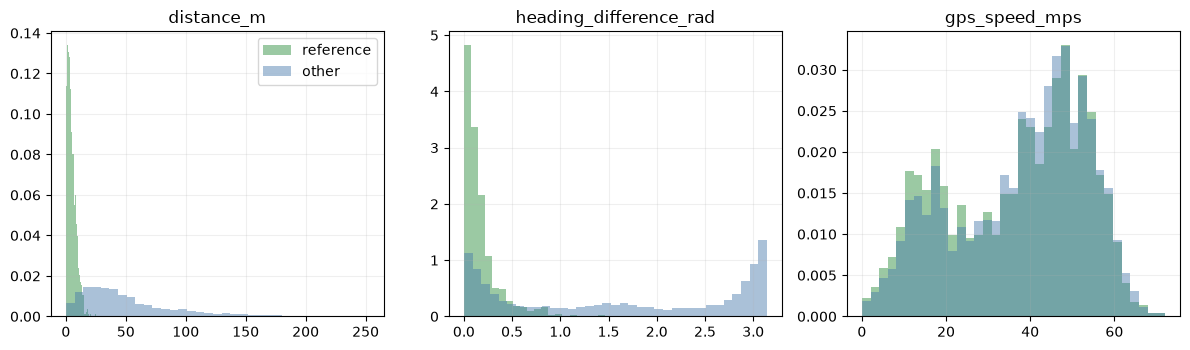

In [6]:
import matplotlib.pyplot as plt
fig,axs=plt.subplots(1,3,figsize=(12,3.6))
for ax,feature in zip(axs,["distance_m","heading_difference_rad","gps_speed_mps"]):
  for label,color in [(True,"#228833"),(False,"#4477AA")]:
    vals=long.loc[long.is_reference_candidate==label,feature].to_numpy()
    ax.hist(vals,bins=35,density=True,alpha=.45,label="reference" if label else "other",color=color)
  ax.set_title(feature);ax.grid(alpha=.2)
axs[0].legend();fig.tight_layout()

## Why these five features?

1. **Distance to segment (m):** the main physical proximity cue for noisy GPS.
2. **Heading difference (radians):** separates nearby parallel or opposite-direction roads.
3. **Along-segment fraction (0–1):** indicates whether a point projects within the candidate segment’s span.
4. **Segment length (m):** gives geometric context for distance and endpoint position.
5. **GPS speed (m/s):** adds movement context and divides displacement by actual elapsed seconds.

The first two features are directly tied to GPS-to-road alignment; along-segment position and length describe candidate geometry; speed adds temporal movement context. This is an initial task-based set, not a claim that feature selection is complete.

## Step 4 — Check feature redundancy on this trip

A correlation table is descriptive only: correlated inputs do not automatically need to be removed from tree models. The model-training notebook adds permutation importance on the held-out training trips to measure each feature’s predictive contribution.

In [7]:
display(long[FEATURE_NAMES].corr().round(2))

,distance_m,heading_difference_rad,along_segment_fraction,segment_length_m,gps_speed_mps
distance_m,1.00,0.07,-0.00,-0.09,0.25
heading_difference_rad,0.07,1.00,0.01,0.02,0.01
along_segment_fraction,-0.00,0.01,1.00,0.00,-0.01
segment_length_m,-0.09,0.02,0.00,1.00,0.16
gps_speed_mps,0.25,0.01,-0.01,0.16,1.00
